# Credit Card Approval Prediction EDA

*We are trying to predict to whom to approve the credit card.*

Credit score cards are a common risk control method in the financial industry. It uses personal information and data submitted by credit card applicants to predict the probability of future defaults and credit card borrowings. The bank is able to decide whether to issue a credit card to the applicant. Credit scores can objectively quantify the magnitude of risk.
 
Generally speaking, credit score cards are based on historical data. Once encountering large economic fluctuations. Past models may lose their original predictive power. Logistic model is a common method for credit scoring.  We will be aso using Boosting, Random Forest, and Support Vector Machines to form the model and make comparision. Then choosing the best model.

Our objective is to  predict if an applicant is 'good' or 'bad' client. This Machine Learning (ML) task is regression since the label (or target) we are trying to predict is numeric, we derived it from classifying the given column.

The example data is provided by Kaggle at [Credit Card Approval Prediction](https://www.kaggle.com/datasets/rikdifos/credit-card-approval-prediction?select=application_record.csv).

#### Load Your Data
Now that we understand what we are trying to do, we need to load our data and describe it, explore it and verify it.

In [2]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import *

spark = SparkSession.builder \
    .appName("CreditCardApproval") \
    .master("local[*]") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate()

print("Spark version:", spark.version)


print(spark)

Spark version: 4.0.1


In [1]:
from pyspark.sql.functions import col, count, when, regexp_extract, stddev, countDistinct
from pyspark.ml.feature import StringIndexer, OneHotEncoder
from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler


In [3]:
# Path to our files
file_path1 = "file:///H:/Documents/Bigdata_course/Credit Card Approval/application_record.csv"

app_df = (spark.read
    .option("header", True)      # first row as header
    .csv(file_path1)
    )
app_df.printSchema()
app_df.show(5)



root
 |-- ID: string (nullable = true)
 |-- CODE_GENDER: string (nullable = true)
 |-- FLAG_OWN_CAR: string (nullable = true)
 |-- FLAG_OWN_REALTY: string (nullable = true)
 |-- CNT_CHILDREN: string (nullable = true)
 |-- AMT_INCOME_TOTAL: string (nullable = true)
 |-- NAME_INCOME_TYPE: string (nullable = true)
 |-- NAME_EDUCATION_TYPE: string (nullable = true)
 |-- NAME_FAMILY_STATUS: string (nullable = true)
 |-- NAME_HOUSING_TYPE: string (nullable = true)
 |-- DAYS_BIRTH: string (nullable = true)
 |-- DAYS_EMPLOYED: string (nullable = true)
 |-- FLAG_MOBIL: string (nullable = true)
 |-- FLAG_WORK_PHONE: string (nullable = true)
 |-- FLAG_PHONE: string (nullable = true)
 |-- FLAG_EMAIL: string (nullable = true)
 |-- OCCUPATION_TYPE: string (nullable = true)
 |-- CNT_FAM_MEMBERS: string (nullable = true)

+-------+-----------+------------+---------------+------------+----------------+--------------------+--------------------+--------------------+-----------------+----------+----------

In [4]:
file_path2 = "file:///H:/Documents/Bigdata_course/Credit Card Approval/credit_record.csv"

crd_df = (spark.read
    .option("header", True)      # first row as header
    .csv(file_path2)
    )

crd_df.printSchema()
crd_df.show(5)

root
 |-- ID: string (nullable = true)
 |-- MONTHS_BALANCE: string (nullable = true)
 |-- STATUS: string (nullable = true)

+-------+--------------+------+
|     ID|MONTHS_BALANCE|STATUS|
+-------+--------------+------+
|5001711|             0|     X|
|5001711|            -1|     0|
|5001711|            -2|     0|
|5001711|            -3|     0|
|5001712|             0|     C|
+-------+--------------+------+
only showing top 5 rows


In [5]:
from pyspark.sql.functions import col, when, max as spark_max

# Create a 'label' column: 1 if STATUS >= 3 ever, else 0
crd_df = crd_df.withColumn(
    "bad_status",
    when(col("STATUS").isin(['3','4','5']), 1).otherwise(0)
)

# Aggregate per ID to get final label
label_df = crd_df.groupBy("ID").agg(spark_max("bad_status").alias("label"))

label_df.show(5)


+-------+-----+
|     ID|label|
+-------+-----+
|5001730|    0|
|5001734|    0|
|5001745|    0|
|5001768|    0|
|5001798|    0|
+-------+-----+
only showing top 5 rows


In [6]:
# Join application features with label
data = app_df.join(label_df, on="ID", how="inner")



In [7]:
#looking the schema
data.printSchema()

root
 |-- ID: string (nullable = true)
 |-- CODE_GENDER: string (nullable = true)
 |-- FLAG_OWN_CAR: string (nullable = true)
 |-- FLAG_OWN_REALTY: string (nullable = true)
 |-- CNT_CHILDREN: string (nullable = true)
 |-- AMT_INCOME_TOTAL: string (nullable = true)
 |-- NAME_INCOME_TYPE: string (nullable = true)
 |-- NAME_EDUCATION_TYPE: string (nullable = true)
 |-- NAME_FAMILY_STATUS: string (nullable = true)
 |-- NAME_HOUSING_TYPE: string (nullable = true)
 |-- DAYS_BIRTH: string (nullable = true)
 |-- DAYS_EMPLOYED: string (nullable = true)
 |-- FLAG_MOBIL: string (nullable = true)
 |-- FLAG_WORK_PHONE: string (nullable = true)
 |-- FLAG_PHONE: string (nullable = true)
 |-- FLAG_EMAIL: string (nullable = true)
 |-- OCCUPATION_TYPE: string (nullable = true)
 |-- CNT_FAM_MEMBERS: string (nullable = true)
 |-- label: integer (nullable = true)



## EDA

In [8]:
#Shape

print(f"No. of Rows: {data.count()}")
print(f"No. of Column: {len(data.columns)}")

No. of Rows: 36457
No. of Column: 19


In [9]:
# Target Distribution
data.groupBy("label").count().show()

+-----+-----+
|label|count|
+-----+-----+
|    1|  302|
|    0|36155|
+-----+-----+



In [10]:
# Missing Values 

for col_name in data.columns:
    missing = data.filter(col(col_name).isNull()).count()
    print(f"{col_name}: {missing} missing")

ID: 0 missing
CODE_GENDER: 0 missing
FLAG_OWN_CAR: 0 missing
FLAG_OWN_REALTY: 0 missing
CNT_CHILDREN: 0 missing
AMT_INCOME_TOTAL: 0 missing
NAME_INCOME_TYPE: 0 missing
NAME_EDUCATION_TYPE: 0 missing
NAME_FAMILY_STATUS: 0 missing
NAME_HOUSING_TYPE: 0 missing
DAYS_BIRTH: 0 missing
DAYS_EMPLOYED: 0 missing
FLAG_MOBIL: 0 missing
FLAG_WORK_PHONE: 0 missing
FLAG_PHONE: 0 missing
FLAG_EMAIL: 0 missing
OCCUPATION_TYPE: 11323 missing
CNT_FAM_MEMBERS: 0 missing
label: 0 missing


#### Descriptive Statistics

In [11]:
#Summary Statistics
data.describe().show()

+-------+-----------------+-----------+------------+---------------+-------------------+------------------+--------------------+--------------------+------------------+-----------------+------------------+------------------+----------+-------------------+-------------------+-------------------+--------------------+------------------+--------------------+
|summary|               ID|CODE_GENDER|FLAG_OWN_CAR|FLAG_OWN_REALTY|       CNT_CHILDREN|  AMT_INCOME_TOTAL|    NAME_INCOME_TYPE| NAME_EDUCATION_TYPE|NAME_FAMILY_STATUS|NAME_HOUSING_TYPE|        DAYS_BIRTH|     DAYS_EMPLOYED|FLAG_MOBIL|    FLAG_WORK_PHONE|         FLAG_PHONE|         FLAG_EMAIL|     OCCUPATION_TYPE|   CNT_FAM_MEMBERS|               label|
+-------+-----------------+-----------+------------+---------------+-------------------+------------------+--------------------+--------------------+------------------+-----------------+------------------+------------------+----------+-------------------+-------------------+-----------

#### Target Variable Analysis

In [12]:
# Class Balance

data.groupBy("label").count().show()

+-----+-----+
|label|count|
+-----+-----+
|    1|  302|
|    0|36155|
+-----+-----+



In [15]:
# Class Ratio

data.groupBy("label").count()\
    .withColumn("ratio", col("count")/data.count())\
    .show()

+-----+-----+--------------------+
|label|count|               ratio|
+-----+-----+--------------------+
|    1|  302|0.008283731519324135|
|    0|36155|  0.9917162684806758|
+-----+-----+--------------------+



From the above table it can be observed that the number of the people with bad status is 0.8% while the number of people with good status is 99%. This shows that the dataset is highly imbalance. So, there are two ways to balance the data; one is Downsampling and another is Oversampling. In this case, if we do downsampling, then majority of the data will be lost due to which the model can not be trained well. Thus, we will choose Oversampling as it will keep the data having the value 0 that will help model the learn the actual pattern.

#### Categorical Value Count

In [40]:
from pyspark.sql.types import StringType
# List all string/categorical columns:

cat_cols = [f.name for f in data.schema.fields if isinstance(f.dataType, StringType)]
cat_cols

#for each category

for c in cat_cols:
    print("\n" + "="*60)
    print(f"CATEGORICAL COLUMN: {c}")
    print("="*60)
    data.groupBy(c).count().orderBy("count", ascending=False).show(truncate=False)


CATEGORICAL COLUMN: CODE_GENDER
+-----------+-----+
|CODE_GENDER|count|
+-----------+-----+
|F          |24430|
|M          |12027|
+-----------+-----+


CATEGORICAL COLUMN: FLAG_OWN_CAR
+------------+-----+
|FLAG_OWN_CAR|count|
+------------+-----+
|N           |22614|
|Y           |13843|
+------------+-----+


CATEGORICAL COLUMN: FLAG_OWN_REALTY
+---------------+-----+
|FLAG_OWN_REALTY|count|
+---------------+-----+
|Y              |24506|
|N              |11951|
+---------------+-----+


CATEGORICAL COLUMN: NAME_INCOME_TYPE
+--------------------+-----+
|NAME_INCOME_TYPE    |count|
+--------------------+-----+
|Working             |18819|
|Commercial associate|8490 |
|Pensioner           |6152 |
|State servant       |2985 |
|Student             |11   |
+--------------------+-----+


CATEGORICAL COLUMN: NAME_EDUCATION_TYPE
+-----------------------------+-----+
|NAME_EDUCATION_TYPE          |count|
+-----------------------------+-----+
|Secondary / secondary special|24777|
|Higher ed

#### Distribution for the Numeric column

In [42]:
# List all numeric columns:

num_cols = [f.name for f in data.schema.fields if isinstance(f.dataType, NumericType)]
num_cols = [c for c in num_cols if c != "ID"]

#for each category

for c in num_cols:
    data.select(c).describe().show()

+-------+-------------------+
|summary|       CNT_CHILDREN|
+-------+-------------------+
|  count|              36457|
|   mean|0.43031516581177826|
| stddev| 0.7423669007186845|
|    min|                  0|
|    max|                 19|
+-------+-------------------+

+-------+------------------+
|summary|  AMT_INCOME_TOTAL|
+-------+------------------+
|  count|             36457|
|   mean|186685.73666236937|
| stddev|101789.22648234662|
|    min|           27000.0|
|    max|         1575000.0|
+-------+------------------+

+-------+------------------+
|summary|        DAYS_BIRTH|
+-------+------------------+
|  count|             36457|
|   mean|-15975.17338234084|
| stddev| 4200.549943759219|
|    min|            -25152|
|    max|             -7489|
+-------+------------------+

+-------+------------------+
|summary|     DAYS_EMPLOYED|
+-------+------------------+
|  count|             36457|
|   mean|59262.935567929344|
| stddev| 137651.3348588564|
|    min|            -15713|
| 

#### Correlation among Numeric Features

In [30]:
# List of columns you want to convert
columns_to_cast = {
    "ID": "integer",
    "CNT_CHILDREN": "integer",
    "AMT_INCOME_TOTAL": "double",
    "DAYS_BIRTH": "integer",
    "DAYS_EMPLOYED": "integer",
    "FLAG_MOBIL": "integer",
    "FLAG_WORK_PHONE": "integer",
    "FLAG_PHONE": "integer",
    "FLAG_EMAIL": "integer",
    "CNT_FAM_MEMBERS": "double"
}

# Cast the columns
for column, dtype in columns_to_cast.items():
    data = data.withColumn(column, col(column).cast(dtype))

# Verify the new schema
data.printSchema()


root
 |-- ID: integer (nullable = true)
 |-- CODE_GENDER: string (nullable = true)
 |-- FLAG_OWN_CAR: string (nullable = true)
 |-- FLAG_OWN_REALTY: string (nullable = true)
 |-- CNT_CHILDREN: integer (nullable = true)
 |-- AMT_INCOME_TOTAL: double (nullable = true)
 |-- NAME_INCOME_TYPE: string (nullable = true)
 |-- NAME_EDUCATION_TYPE: string (nullable = true)
 |-- NAME_FAMILY_STATUS: string (nullable = true)
 |-- NAME_HOUSING_TYPE: string (nullable = true)
 |-- DAYS_BIRTH: integer (nullable = true)
 |-- DAYS_EMPLOYED: integer (nullable = true)
 |-- FLAG_MOBIL: integer (nullable = true)
 |-- FLAG_WORK_PHONE: integer (nullable = true)
 |-- FLAG_PHONE: integer (nullable = true)
 |-- FLAG_EMAIL: integer (nullable = true)
 |-- OCCUPATION_TYPE: string (nullable = true)
 |-- CNT_FAM_MEMBERS: double (nullable = true)
 |-- label: integer (nullable = true)



{"ts": "2026-01-10 15:29:31.232", "level": "ERROR", "logger": "DataFrameQueryContextLogger", "msg": "[DIVIDE_BY_ZERO] Division by zero. Use `try_divide` to tolerate divisor being 0 and return NULL instead. If necessary set \"spark.sql.ansi.enabled\" to \"false\" to bypass this error. SQLSTATE: 22012", "context": {"file": "jdk.internal.reflect.GeneratedMethodAccessor165.invoke(Unknown Source)", "line": "", "fragment": "corr", "errorClass": "DIVIDE_BY_ZERO"}, "exception": {"class": "Py4JJavaError", "msg": "An error occurred while calling o852.corr.\n: org.apache.spark.SparkArithmeticException: [DIVIDE_BY_ZERO] Division by zero. Use `try_divide` to tolerate divisor being 0 and return NULL instead. If necessary set \"spark.sql.ansi.enabled\" to \"false\" to bypass this error. SQLSTATE: 22012\n== DataFrame ==\n\"corr\" was called from\njdk.internal.reflect.GeneratedMethodAccessor165.invoke(Unknown Source)\n\r\n\tat org.apache.spark.sql.errors.QueryExecutionErrors$.divideByZeroError(QueryExe

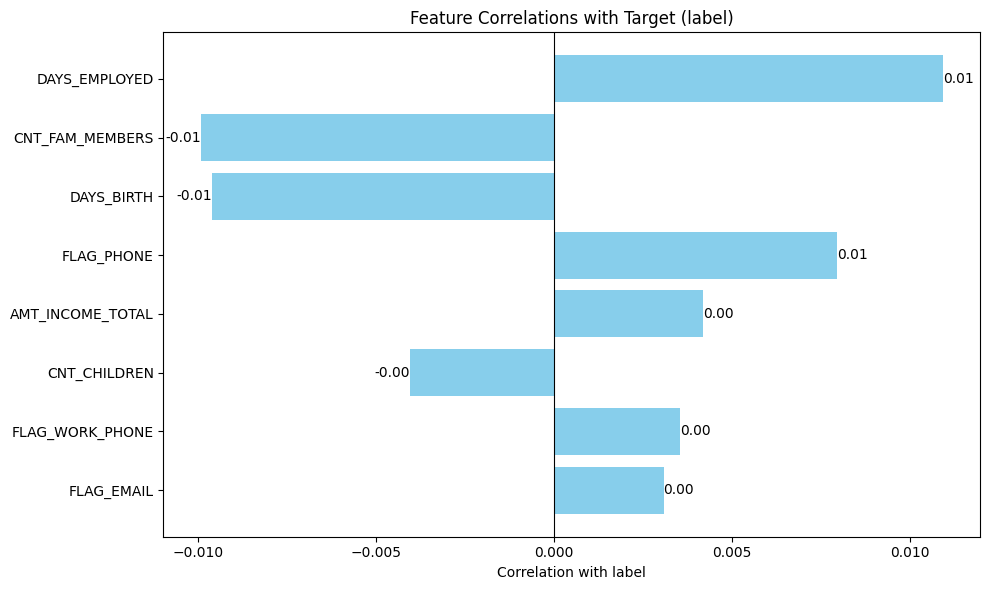

In [43]:


# -----------------------------
# Correlation of all columns with target + Visualization (fixed abs)
# -----------------------------
import matplotlib.pyplot as plt
import numpy as np
import builtins  # to access Python's built-in abs
from pyspark.sql.types import NumericType

target_col = "label"

# Collect numeric columns properly
numeric_cols = [f.name for f in data.schema.fields if isinstance(f.dataType, NumericType)]

# Remove target itself from the list
feature_cols = [c for c in numeric_cols if c not in {target_col, "ID"}]

# Compute correlations and store them
"""
correlations = []
for c in feature_cols:
    corr_value = data.stat.corr(c, target_col)
    if corr_value is not None and not np.isnan(corr_value):
        correlations.append((c, float(corr_value)))  # ensure plain float
"""
correlations = []

for c in feature_cols:
    try:
        corr_value = data.stat.corr(c, target_col)
        if corr_value is not None and not np.isnan(corr_value):
            correlations.append((c, float(corr_value)))
    except Exception:
        pass  # skip problematic columns safely


# If no correlations found, stop
if not correlations:
    print("No numeric correlations could be computed.")
else:
    # Sort by absolute correlation using Python's built-in abs
    correlations.sort(key=lambda x: builtins.abs(x[1]), reverse=True)

    # Prepare data for plotting
    features = [f[0] for f in correlations]
    values = [f[1] for f in correlations]

    # Plot
    plt.figure(figsize=(10, 6))
    bars = plt.barh(features[::-1], values[::-1], color="skyblue")  # reverse for top-down order
    plt.xlabel(f"Correlation with {target_col}")
    plt.title("Feature Correlations with Target (label)")
    plt.axvline(0, color="black", linewidth=0.8)

    # Add labels to bars
    for bar, val in zip(bars, values[::-1]):
        plt.text(val, bar.get_y() + bar.get_height()/2,
                 f"{val:.2f}", va='center', ha='left' if val > 0 else 'right')

    plt.tight_layout()
    plt.show()
